In [1]:
import pandas as pd
import numpy as np

In [2]:
# import model
from sklearn.linear_model import LinearRegression

# for splitting
from sklearn.model_selection import train_test_split

# for scaling of data
from sklearn.preprocessing import StandardScaler

# import metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [7]:
df=pd.read_csv('data/gold_price_data.csv')

In [8]:
df.head()

,Date,SPX,GLD,USO,SLV,EUR/USD
0,1/2/2008,1447.160034,84.860001,78.470001,15.180,1.471692
1,1/3/2008,1447.160034,85.570000,78.370003,15.285,1.474491
2,1/4/2008,1411.630005,85.129997,77.309998,15.167,1.475492
3,1/7/2008,1416.180054,84.769997,75.500000,15.053,1.468299
4,1/8/2008,1390.189941,86.779999,76.059998,15.590,1.557099


In [9]:
df.tail()

,Date,SPX,GLD,USO,SLV,EUR/USD
2285,5/8/2018,2671.919922,124.589996,14.0600,15.5100,1.186789
2286,5/9/2018,2697.790039,124.330002,14.3700,15.5300,1.184722
2287,5/10/2018,2723.070068,125.180000,14.4100,15.7400,1.191753
2288,5/14/2018,2730.129883,124.489998,14.3800,15.5600,1.193118
2289,5/16/2018,2725.780029,122.543800,14.4058,15.4542,1.182033


In [10]:
df.count()

Date       2290
SPX        2290
GLD        2290
USO        2290
SLV        2290
EUR/USD    2290
dtype: int64

In [11]:
df.isnull().sum()

Date       0
SPX        0
GLD        0
USO        0
SLV        0
EUR/USD    0
dtype: int64

In [12]:
df.isnull()

,Date,SPX,GLD,USO,SLV,EUR/USD
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,False,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False
...,...,...,...,...,...,...
2285,False,False,False,False,False,False
2286,False,False,False,False,False,False
2287,False,False,False,False,False,False
2288,False,False,False,False,False,False


In [13]:
df['Date'].unique()

<ArrowStringArray>
[ '1/2/2008',  '1/3/2008',  '1/4/2008',  '1/7/2008',  '1/8/2008',  '1/9/2008',
 '1/10/2008', '1/11/2008', '1/14/2008', '1/15/2008',
 ...
 '4/30/2018',  '5/1/2018',  '5/2/2018',  '5/3/2018',  '5/7/2018',  '5/8/2018',
  '5/9/2018', '5/10/2018', '5/14/2018', '5/16/2018']
Length: 2290, dtype: str

In [14]:
df.columns

Index(['Date', 'SPX', 'GLD', 'USO', 'SLV', 'EUR/USD'], dtype='str')

In [15]:
df.dtypes

Date           str
SPX        float64
GLD        float64
USO        float64
SLV        float64
EUR/USD    float64
dtype: object

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
2285    False
2286    False
2287    False
2288    False
2289    False
Length: 2290, dtype: bool

In [18]:
df.describe()

,SPX,GLD,USO,SLV,EUR/USD
count,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000
mean,1654.315776,122.732875,31.842221,20.084997,1.283653
std,519.111540,23.283346,19.523517,7.092566,0.131547
min,676.530029,70.000000,7.960000,8.850000,1.039047
25%,1239.874969,109.725000,14.380000,15.570000,1.171313
50%,1551.434998,120.580002,33.869999,17.268500,1.303297
75%,2073.010070,132.840004,37.827501,22.882500,1.369971
max,2872.870117,184.589996,117.480003,47.259998,1.598798


In [19]:
df['GLD'].skew()

np.float64(0.3341383472692508)

In [20]:
df['GLD'].median()

np.float64(120.580002)

In [21]:
df['Date']= pd.to_datetime(df['Date'])

In [22]:
df['Year']=df['Date'].dt.year

In [23]:
df.head()

,Date,SPX,GLD,USO,SLV,EUR/USD,Year
0,2008-01-02,1447.160034,84.860001,78.470001,15.180,1.471692,2008
1,2008-01-03,1447.160034,85.570000,78.370003,15.285,1.474491,2008
2,2008-01-04,1411.630005,85.129997,77.309998,15.167,1.475492,2008
3,2008-01-07,1416.180054,84.769997,75.500000,15.053,1.468299,2008
4,2008-01-08,1390.189941,86.779999,76.059998,15.590,1.557099,2008


In [24]:
df.dtypes

Date       datetime64[us]
SPX               float64
GLD               float64
USO               float64
SLV               float64
EUR/USD           float64
Year                int32
dtype: object

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

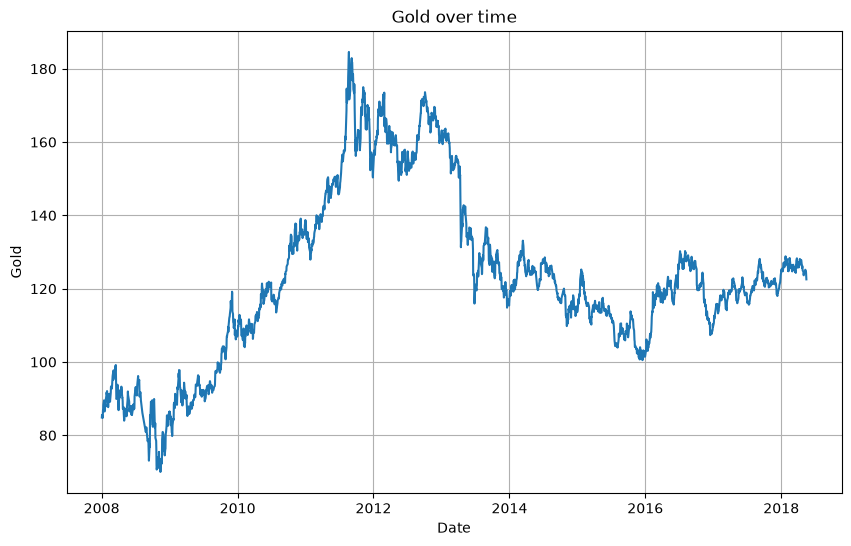

In [26]:
plt.figure(figsize=(10,6))
plt.plot(df['Date'], df['GLD'])
plt.xlabel('Date')
plt.ylabel('Gold')
plt.title('Gold over time')
plt.grid()

plt.show()

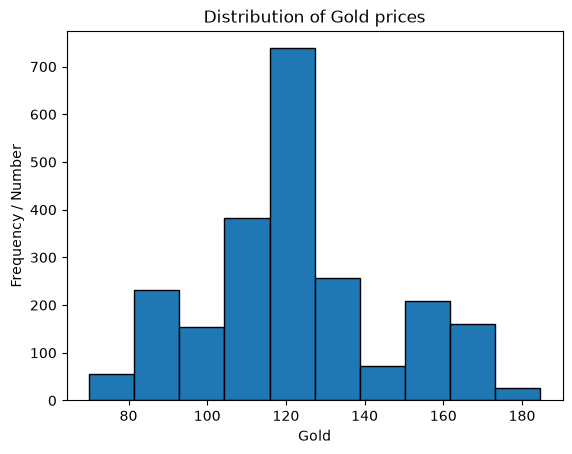

In [27]:
plt.hist( df['GLD'], edgecolor= 'black')
plt.xlabel('Gold')
plt.ylabel('Frequency / Number')
plt.title('Distribution of Gold prices')
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_5652\739876081.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['Year'],y= df['GLD'], palette="Set2")


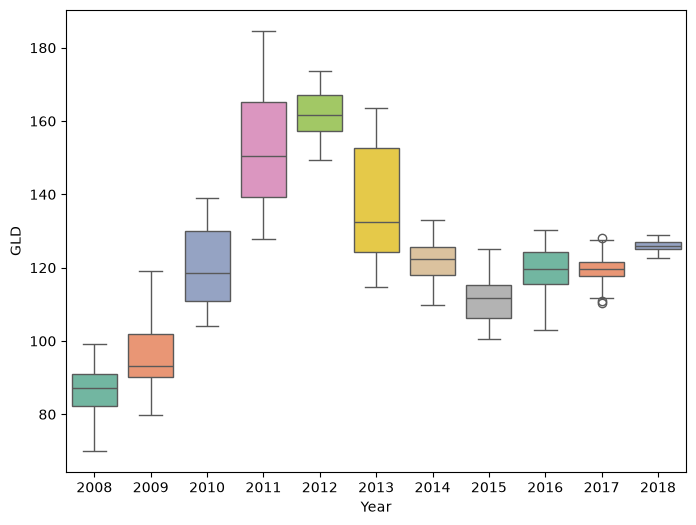

In [28]:
plt.figure(figsize=(8,6))
sns.boxplot(x=df['Year'],y= df['GLD'], palette="Set2")
plt.show()

In [29]:
corr_columns=df.select_dtypes(['int','float'])
corr_columns = corr_columns.drop(columns='Year')
corr_columns

,SPX,GLD,USO,SLV,EUR/USD
0,1447.160034,84.860001,78.470001,15.1800,1.471692
1,1447.160034,85.570000,78.370003,15.2850,1.474491
2,1411.630005,85.129997,77.309998,15.1670,1.475492
3,1416.180054,84.769997,75.500000,15.0530,1.468299
4,1390.189941,86.779999,76.059998,15.5900,1.557099
...,...,...,...,...,...
2285,2671.919922,124.589996,14.060000,15.5100,1.186789
2286,2697.790039,124.330002,14.370000,15.5300,1.184722
2287,2723.070068,125.180000,14.410000,15.7400,1.191753
2288,2730.129883,124.489998,14.380000,15.5600,1.193118


In [30]:
corr_data= corr_columns.corr()   # getting pearson correlation value
corr_data

,SPX,GLD,USO,SLV,EUR/USD
SPX,1.000000,0.049345,-0.591573,-0.274055,-0.672017
GLD,0.049345,1.000000,-0.186360,0.866632,-0.024375
USO,-0.591573,-0.186360,1.000000,0.167547,0.829317
SLV,-0.274055,0.866632,0.167547,1.000000,0.321631
EUR/USD,-0.672017,-0.024375,0.829317,0.321631,1.000000


<Axes: >

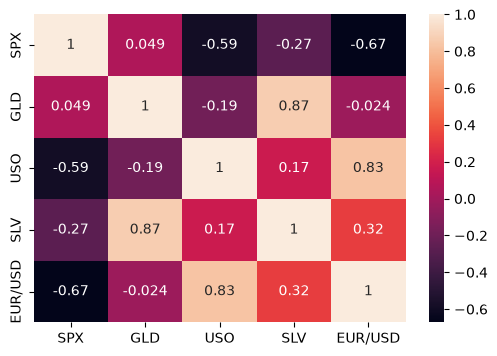

In [31]:
plt.figure(figsize=(6,4))
sns.heatmap(corr_data,annot=True)

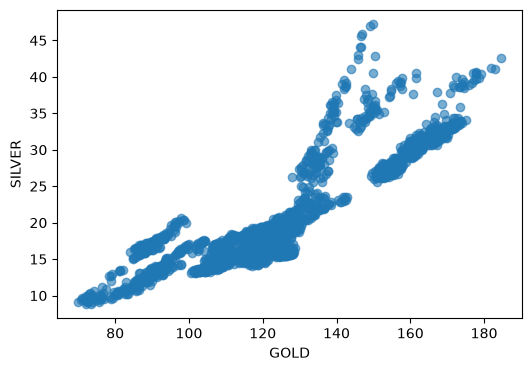

In [32]:
plt.figure(figsize=(6,4))
plt.scatter(df['GLD'],df['SLV'],alpha= 0.6)
plt.xlabel('GOLD')
plt.ylabel('SILVER')
plt.show()

In [33]:
df.columns

Index(['Date', 'SPX', 'GLD', 'USO', 'SLV', 'EUR/USD', 'Year'], dtype='str')

In [34]:
features= [ 'SPX', 'USO', 'SLV', 'EUR/USD']
target=['GLD']

In [35]:
X= df[features]
Y= df[target]

In [36]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size= 0.3, random_state=42,
)

In [37]:
scaler= StandardScaler()
X_train_scale= scaler.fit_transform(X_train)
X_test_scale= scaler.transform(X_test)

In [38]:
model= LinearRegression()

In [39]:
model.fit(X_train_scale,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 4)","[[ 3.41,-4.87,22.28,-1.41]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[122.8]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[63.86,37.76,25.89,15.44]"


In [40]:
Y_pred = model.predict(X_test_scale)

In [41]:
mae= mean_absolute_error(Y_test,Y_pred)
mse= mean_squared_error(Y_test,Y_pred)
rmse= np.sqrt(mse)
r2=r2_score(Y_test,Y_pred)

In [42]:
print(f'Mean Absolute Error: {mae:,.2f}')
print(f'Mean Squared Error: {mse:,.2f}')
print(f'Root Mean Squared Error: {rmse:,.2f}')
print(f'R2 Score: {r2:,.2f}')

Mean Absolute Error: 5.86
Mean Squared Error: 58.06
Root Mean Squared Error: 7.62
R2 Score: 0.89


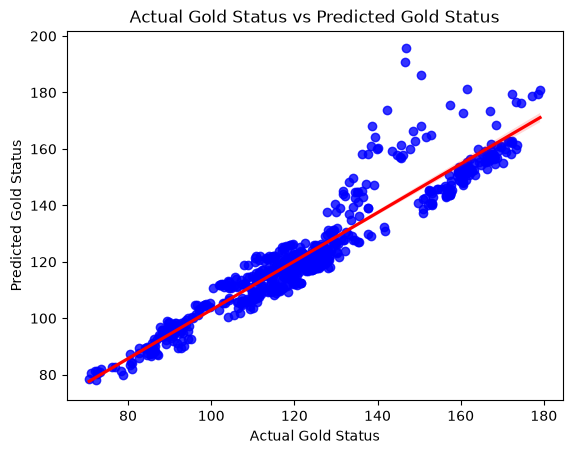

In [43]:
sns.regplot(x= Y_test, y = Y_pred, color= 'blue', line_kws={'color':'red'})
plt.xlabel('Actual Gold Status')
plt.ylabel('Predicted Gold Status')
plt.title('Actual Gold Status vs Predicted Gold Status')
plt.show()

In [44]:
df

,Date,SPX,GLD,USO,SLV,EUR/USD,Year
0,2008-01-02,1447.160034,84.860001,78.470001,15.1800,1.471692,2008
1,2008-01-03,1447.160034,85.570000,78.370003,15.2850,1.474491,2008
2,2008-01-04,1411.630005,85.129997,77.309998,15.1670,1.475492,2008
3,2008-01-07,1416.180054,84.769997,75.500000,15.0530,1.468299,2008
4,2008-01-08,1390.189941,86.779999,76.059998,15.5900,1.557099,2008
...,...,...,...,...,...,...,...
2285,2018-05-08,2671.919922,124.589996,14.060000,15.5100,1.186789,2018
2286,2018-05-09,2697.790039,124.330002,14.370000,15.5300,1.184722,2018
2287,2018-05-10,2723.070068,125.180000,14.410000,15.7400,1.191753,2018
2288,2018-05-14,2730.129883,124.489998,14.380000,15.5600,1.193118,2018


In [45]:
from sklearn.ensemble import RandomForestRegressor

In [46]:
rf_model= RandomForestRegressor()

In [47]:
rf_model.fit(X_train, Y_train)

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [48]:
rf_pred= rf_model.predict(X_test)

In [49]:
rf_mae= mean_absolute_error(Y_test, rf_pred)
rf_mse= mean_squared_error(Y_test, rf_pred)
rf_rmse= np.sqrt(rf_mse)
rf_r2= r2_score(Y_test, rf_pred)

In [50]:
print(f'Mean Absolute Error: {rf_mae:,.2f}')
print(f'Mean Squared Error: {rf_mse:,.2f}')
print(f'Root Mean Squared Error: {rf_rmse:,.2f}')
print(f'R2 Score: {rf_r2:,.2f}')

Mean Absolute Error: 1.33
Mean Squared Error: 5.38
Root Mean Squared Error: 2.32
R2 Score: 0.99


<Axes: xlabel='GLD'>

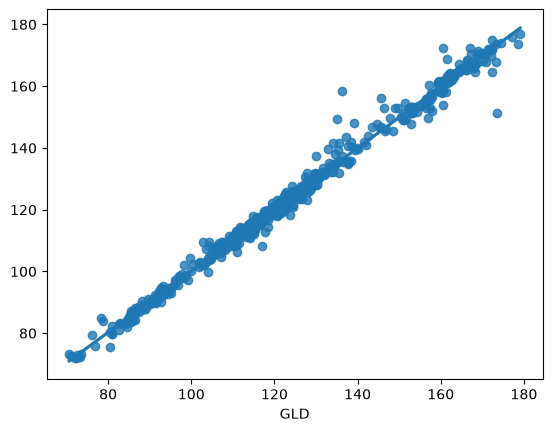

In [51]:
sns.regplot(x= Y_test, y=rf_pred)

In [293]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Predictions on both datasets
train_pred = rf_model.predict(X_train)
test_pred = rf_model.predict(X_test)

# Training performance
print("Training R2:", r2_score(Y_train, train_pred))
print("Training MAE:", mean_absolute_error(Y_train, train_pred))
print("Training RMSE:", np.sqrt(mean_squared_error(Y_train, train_pred)))

# Testing performance
print("\nTesting R2:", r2_score(Y_test, test_pred))
print("Testing MAE:", mean_absolute_error(Y_test, test_pred))
print("Testing RMSE:", np.sqrt(mean_squared_error(Y_test, test_pred)))

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(


Training R2: -1.1211595940061438
Training MAE: 32.3992564813654
Training RMSE: 37.708942711734004

Testing R2: -35.468092382618075
Testing MAE: 28.85258023840614
Testing RMSE: 29.232979393417345
